In [1]:
from pathlib import Path
import os
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from ultralytics import YOLO

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)

## 1. Confirming CUDA is being used

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", GPU_NAME)
print("Device:", DEVICE)

PyTorch: 2.14.0+cu130
CUDA: 13.0
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Device: cuda


## 2. Reproducibility and project paths

In [21]:
SEED = 42

import random

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models" / "yolo_baseline_subset"
REPORT_DIR = PROJECT_ROOT / "reports" / "yolo_baseline_subset"

ANNOTATED_DIR = REPORT_DIR / "annotated"
CROPS_DIR = REPORT_DIR / "crops"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)
CROPS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)


Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development


## 3. Loading the baseline split

In [22]:
df = pd.read_csv(
    DATA_DIR / "interim" / "compcars_resnet50_baseline_split.csv"
)

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

NUM_CLASSES = df["target"].nunique()

class_names = (
    df[["target", "class_name"]]
    .drop_duplicates()
    .sort_values("target")["class_name"]
    .tolist()
)

print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))
print("Classes:", NUM_CLASSES)


Train / Val / Test: 1600 200 200
Classes: 20


## 4. Using the 200-image test subset

In [23]:
eval_df = (
    test_df
    .copy()
    .reset_index(drop=True)
)

print("YOLO baseline images:", len(eval_df))

if "class_name" in eval_df.columns:
    display(
        eval_df["class_name"]
        .value_counts()
        .sort_index()
        .to_frame("images")
    )


YOLO baseline images: 200


,images
class_name,
Audi | Audi A5 coupe,10
Audi | Audi A5 hatchback,10
Audi | Audi A8L,10
BAW | BAW E Series hatchback,10
BWM | BWM 3 Series,10
BWM | BWM 5 Series,10
Benz | Benz E Class,10
Benz | Benz E Class couple,10
Buck | EXCELLE GT,10


## 5. Configuring CompCars image path

In [24]:
DEFAULT_COMPCARS = (
    r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
    r"\capstone-vehicle-metadata\data\compcars_kaggle\extracted"
)

ROOT = Path(os.environ.get("COMPCARS_EXTRACTED", DEFAULT_COMPCARS))

if not ROOT.exists():
    raise FileNotFoundError(f"CompCars path does not exist:\n{ROOT}")

def resolve_local_path(original_path):
    text = str(original_path).replace("\\", "/")

    if "/extracted/" in text:
        relative = text.split("/extracted/", 1)[1]
    elif "/image/" in text:
        relative = "image/" + text.split("/image/", 1)[1]
    else:
        return Path(original_path)

    return ROOT / Path(*relative.split("/"))

for part in [train_df, val_df, test_df]:
    part["local_file_path"] = part["file_path"].map(resolve_local_path)

sample = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
).sample(30, random_state=SEED)

if not sample["local_file_path"].map(Path.exists).all():
    raise FileNotFoundError("Some image paths do not resolve.")

print("Image path mapping looks good.")

# YOLO evaluates the same test subset.
eval_df = (
    test_df
    .copy()
    .reset_index(drop=True)
)

print("YOLO test images ready:", len(eval_df))


Image path mapping looks good.
YOLO test images ready: 200


## 6. Baseline configuration

In [25]:
MODEL_NAMES = [
    "yolo11n.pt",
    "yolo11s.pt",
]

CONF_THRESHOLD = 0.25
NMS_IOU = 0.70
IMAGE_SIZE = 640

TARGET_CLASSES = {
    "car",
    "truck",
    "bus",
}

print("Models:", MODEL_NAMES)
print("Confidence:", CONF_THRESHOLD)
print("Image size:", IMAGE_SIZE)

Models: ['yolo11n.pt', 'yolo11s.pt']
Confidence: 0.25
Image size: 640


## 7. Helper functions

In [26]:
def get_target_class_ids(model, target_names):
    name_to_id = {
        str(name).lower(): int(idx)
        for idx, name in model.names.items()
    }

    missing = [
        name
        for name in target_names
        if name.lower() not in name_to_id
    ]

    if missing:
        raise ValueError(
            f"Missing model classes: {missing}"
        )

    return [
        name_to_id[name.lower()]
        for name in target_names
    ]


def extract_detections(
    result,
    model_name,
    image_path,
):
    rows = []

    if (
        result.boxes is None
        or len(result.boxes) == 0
    ):
        return rows

    boxes = (
        result.boxes.xyxy
        .detach()
        .cpu()
        .numpy()
    )

    scores = (
        result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    classes = (
        result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    for det_id, (
        box,
        score,
        class_id,
    ) in enumerate(
        zip(
            boxes,
            scores,
            classes,
        ),
        start=1,
    ):
        x1, y1, x2, y2 = box.tolist()

        rows.append({
            "model": model_name,
            "image": image_path.name,
            "detection_id": det_id,
            "class_id": int(class_id),
            "class_name": result.names[
                int(class_id)
            ],
            "confidence": float(score),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),
            "box_width": float(x2 - x1),
            "box_height": float(y2 - y1),
        })

    return rows

## 8. Running pretrained YOLO baseline

In [29]:
all_detection_rows = []
image_summary_rows = []
model_summary_rows = []

for model_name in MODEL_NAMES:
    print("\n" + "=" * 80)
    print("MODEL:", model_name)
    print("=" * 80)

    model = YOLO(model_name)

    target_ids = get_target_class_ids(
        model,
        TARGET_CLASSES,
    )

    # Warm-up on first image before timing.
    first_image = str(
        eval_df.loc[
            0,
            "local_file_path",
        ]
    )

    _ = model.predict(
        source=first_image,
        conf=CONF_THRESHOLD,
        iou=NMS_IOU,
        imgsz=IMAGE_SIZE,
        classes=target_ids,
        device=DEVICE,
        verbose=False,
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    total_detections = 0
    images_with_car = 0
    times_ms = []
    confidences = []

    for row in eval_df.itertuples(
        index=False
    ):
        image_path = Path(
            row.local_file_path
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        result = model.predict(
            source=str(image_path),
            conf=CONF_THRESHOLD,
            iou=NMS_IOU,
            imgsz=IMAGE_SIZE,
            classes=target_ids,
            agnostic_nms=True,
            device=DEVICE,
            verbose=False,
        )[0]

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        elapsed_ms = (
            time.perf_counter()
            - start
        ) * 1000.0

        detections = extract_detections(
            result,
            model_name,
            image_path,
        )

        detection_count = len(
            detections
        )

        total_detections += (
            detection_count
        )

        if detection_count > 0:
            images_with_car += 1

        times_ms.append(
            elapsed_ms
        )

        confidences.extend([
            detection["confidence"]
            for detection in detections
        ])

        all_detection_rows.extend(
            detections
        )

        image_summary_rows.append({
            "model": model_name,
            "image": image_path.name,
            "detections": detection_count,
            "detected_at_least_one_vehicle": (
                detection_count > 0
            ),
            "inference_ms": elapsed_ms,
            "max_confidence": (
                max(
                    [
                        d["confidence"]
                        for d in detections
                    ],
                    default=np.nan,
                )
            ),
        })

    model_summary_rows.append({
        "model": model_name,
        "images": len(eval_df),
        "images_with_car": images_with_car,
        "detection_coverage": (
            images_with_car
            / len(eval_df)
        ),
        "total_detections": (
            total_detections
        ),
        "mean_detections_per_image": (
            total_detections
            / len(eval_df)
        ),
        "mean_detection_confidence": (
            float(
                np.mean(confidences)
            )
            if confidences
            else np.nan
        ),
        "mean_inference_ms": float(
            np.mean(times_ms)
        ),
        "median_inference_ms": float(
            np.median(times_ms)
        ),
        "approx_fps": float(
            1000.0
            / np.mean(times_ms)
        ),
    })

detection_df = pd.DataFrame(
    all_detection_rows
)

image_summary_df = pd.DataFrame(
    image_summary_rows
)

model_summary_df = pd.DataFrame(
    model_summary_rows
)

display(model_summary_df)


MODEL: yolo11n.pt

MODEL: yolo11s.pt


,model,images,images_with_car,detection_coverage,total_detections,mean_detections_per_image,mean_detection_confidence,mean_inference_ms,median_inference_ms,approx_fps
0,yolo11n.pt,200,200,1.0,423,2.115,0.718835,32.946557,31.71170,30.352185
1,yolo11s.pt,200,200,1.0,450,2.250,0.768093,31.974405,31.66135,31.275016


## 9. Saving annotated examples and vehicle crops

In [34]:
VISUAL_MODEL = "yolo11s.pt"
VISUAL_CONF = 0.50
VISUAL_SAMPLE_SIZE = min(
    30,
    len(eval_df),
)

visual_df = eval_df.sample(
    n=VISUAL_SAMPLE_SIZE,
    random_state=42,
).reset_index(
    drop=True
)

model = YOLO(
    VISUAL_MODEL
)

target_ids = get_target_class_ids(
    model,
    TARGET_CLASSES,
)

saved_rows = []

for row in visual_df.itertuples(
    index=False
):
    image_path = Path(
        row.local_file_path
    )

    result = model.predict(
        source=str(image_path),
        conf=VISUAL_CONF,
        iou=NMS_IOU,
        imgsz=IMAGE_SIZE,
        classes=target_ids,
        device=DEVICE,
        verbose=False,
    )[0]
    # Annotated image
    plotted_bgr = result.plot()
    plotted_rgb = (
        plotted_bgr[..., ::-1]
    )

    annotated_path = (
        ANNOTATED_DIR
        / (
            image_path.stem
            + "_annotated.jpg"
        )
    )

    Image.fromarray(
        plotted_rgb
    ).save(
        annotated_path,
        quality=95,
    )
    # Individual crops
    original_image = Image.open(
        image_path
    ).convert(
        "RGB"
    )

    crop_paths = []

    if (
        result.boxes is not None
        and len(result.boxes) > 0
    ):
        boxes = (
            result.boxes.xyxy
            .detach()
            .cpu()
            .numpy()
        )

        scores = (
            result.boxes.conf
            .detach()
            .cpu()
            .numpy()
        )

        for i, (
            box,
            score,
        ) in enumerate(
            zip(
                boxes,
                scores,
            ),
            start=1,
        ):
            x1, y1, x2, y2 = box

            x1 = max(
                0,
                int(round(x1)),
            )

            y1 = max(
                0,
                int(round(y1)),
            )

            x2 = min(
                original_image.width,
                int(round(x2)),
            )

            y2 = min(
                original_image.height,
                int(round(y2)),
            )

            if x2 <= x1 or y2 <= y1:
                continue

            crop = original_image.crop(
                (
                    x1,
                    y1,
                    x2,
                    y2,
                )
            )

            crop_path = (
                CROPS_DIR
                / (
                    f"{image_path.stem}"
                    f"_car_{i}"
                    f"_conf_{score:.2f}.jpg"
                )
            )

            crop.save(
                crop_path,
                quality=95,
            )

            crop_paths.append(
                str(crop_path)
            )

    saved_rows.append({
        "image": image_path.name,
        "annotated_path": str(
            annotated_path
        ),
        "crop_count": len(
            crop_paths
        ),
    })

visual_outputs_df = pd.DataFrame(
    saved_rows
)

display(
    visual_outputs_df.head()
)

print(
    "Annotated images:",
    ANNOTATED_DIR,
)

print(
    "Vehicle crops:",
    CROPS_DIR,
)

,image,annotated_path,crop_count
0,0d901f992176f5.jpg,C:\Users\elesh\Academics\UTS\36127InnovationLa...,1
1,a6df5c52024b5d.jpg,C:\Users\elesh\Academics\UTS\36127InnovationLa...,2
2,bbc56e44410065.jpg,C:\Users\elesh\Academics\UTS\36127InnovationLa...,3
3,81e8e784b1790f.jpg,C:\Users\elesh\Academics\UTS\36127InnovationLa...,2
4,427764696cea47.jpg,C:\Users\elesh\Academics\UTS\36127InnovationLa...,2


Annotated images: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\yolo_baseline_subset\annotated
Vehicle crops: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\yolo_baseline_subset\crops


## 10. Viewing annotated images

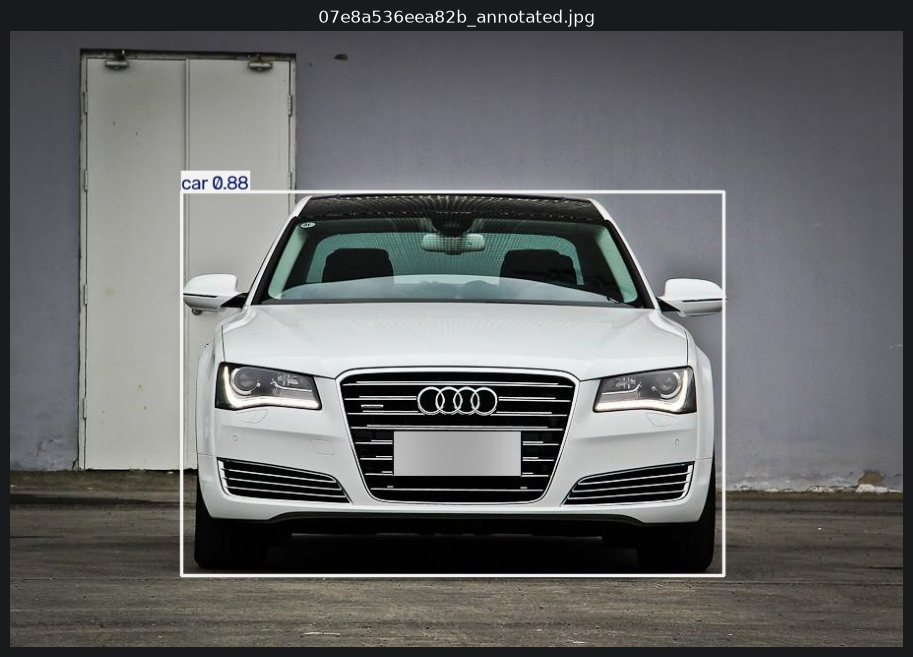

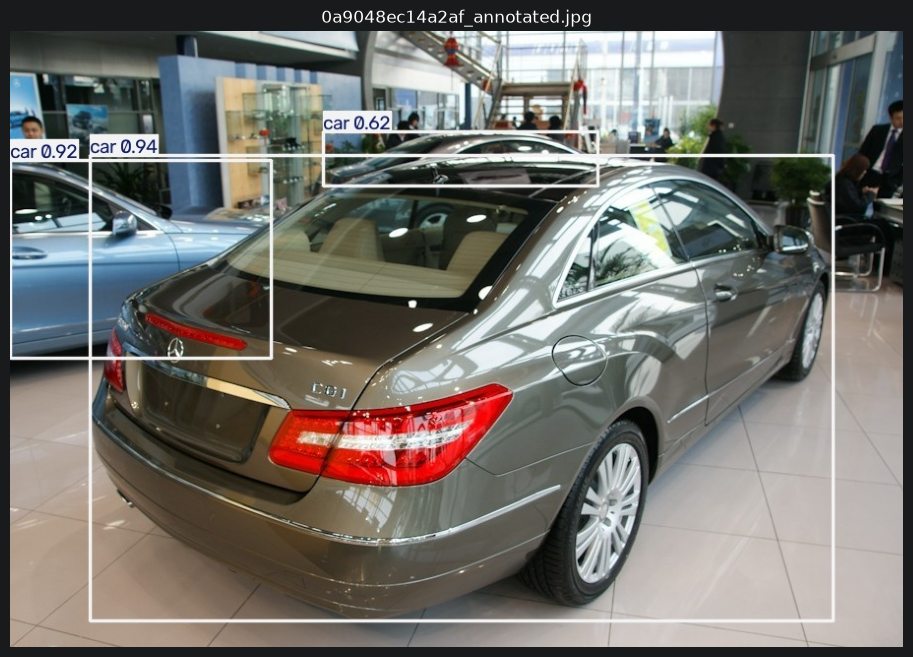

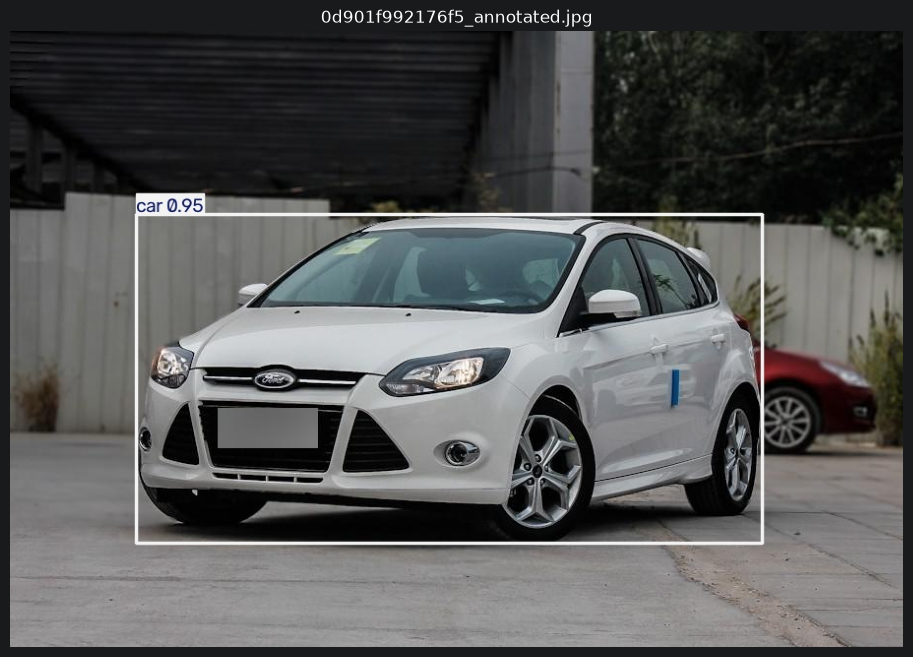

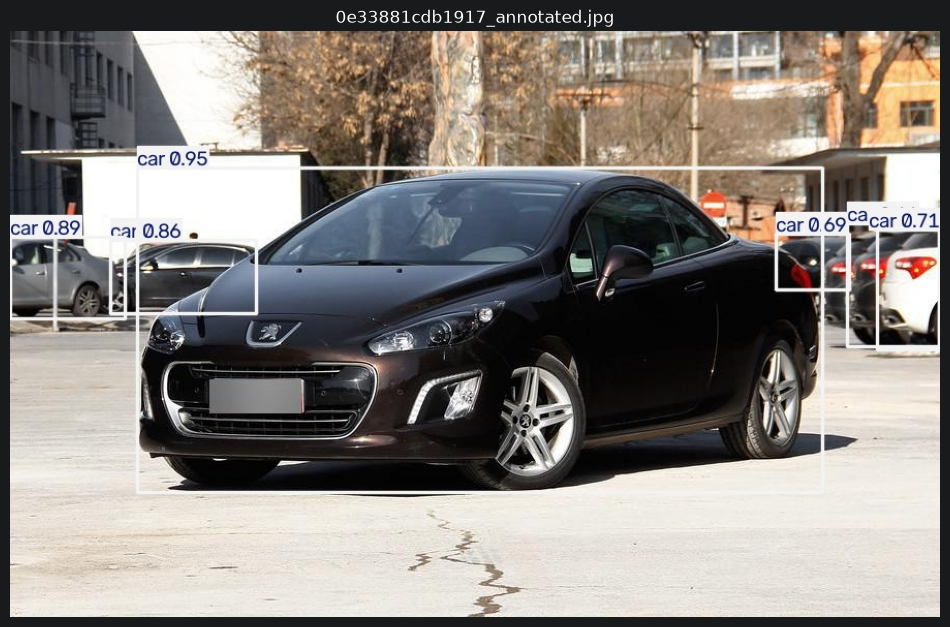

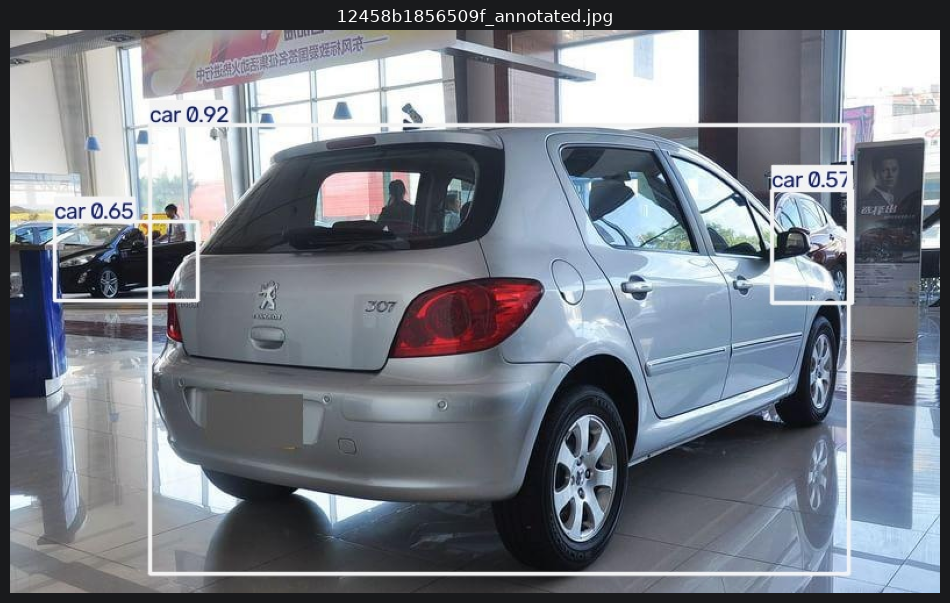

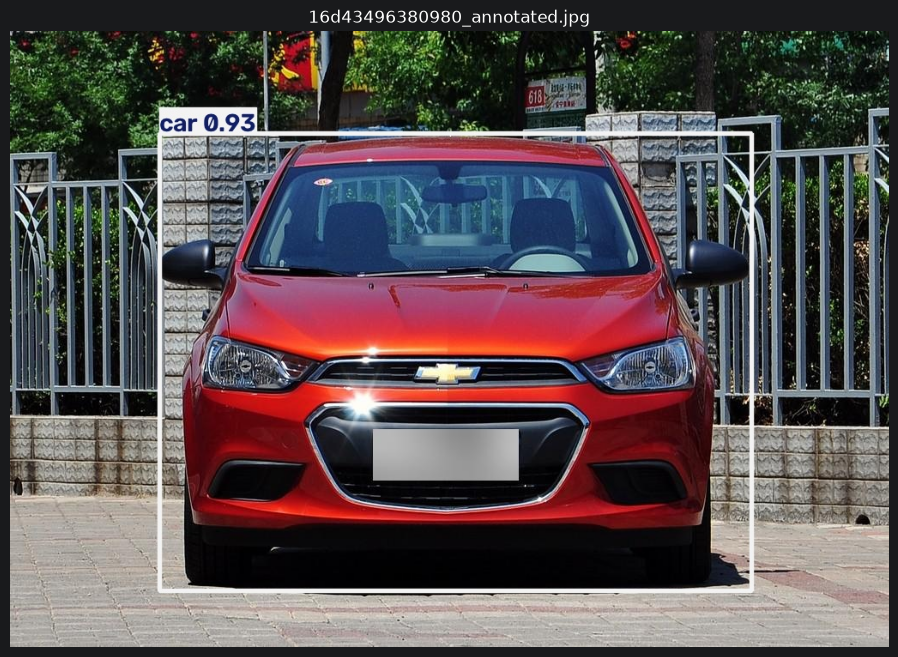

In [35]:
preview_paths = list(
    ANNOTATED_DIR.glob(
        "*.jpg"
    )
)[:6]

for path in preview_paths:
    image = Image.open(
        path
    )

    plt.figure(
        figsize=(12, 8)
    )

    plt.imshow(
        image
    )

    plt.title(
        path.name
    )

    plt.axis(
        "off"
    )

    plt.show()

## 11. Confidence threshold comparison


In [36]:
THRESHOLDS = [
    0.15,
    0.25,
    0.40,
    0.50,
]

THRESHOLD_MODEL = "yolo11s.pt"

model = YOLO(
    THRESHOLD_MODEL
)

target_ids = get_target_class_ids(
    model,
    TARGET_CLASSES,
)

threshold_rows = []

for threshold in THRESHOLDS:
    images_with_car = 0
    total_detections = 0

    for row in eval_df.itertuples(
        index=False
    ):
        result = model.predict(
            source=str(
                row.local_file_path
            ),
            conf=threshold,
            iou=NMS_IOU,
            imgsz=IMAGE_SIZE,
            classes=target_ids,
            device=DEVICE,
            verbose=False,
        )[0]

        count = (
            0
            if result.boxes is None
            else len(result.boxes)
        )

        total_detections += count

        if count > 0:
            images_with_car += 1

    threshold_rows.append({
        "model": THRESHOLD_MODEL,
        "confidence_threshold": (
            threshold
        ),
        "images_with_car": (
            images_with_car
        ),
        "total_images": len(
            eval_df
        ),
        "detection_coverage": (
            images_with_car
            / len(eval_df)
        ),
        "total_detections": (
            total_detections
        ),
    })

threshold_df = pd.DataFrame(
    threshold_rows
)

display(
    threshold_df
)

,model,confidence_threshold,images_with_car,total_images,detection_coverage,total_detections
0,yolo11s.pt,0.15,200,200,1.0,516
1,yolo11s.pt,0.25,200,200,1.0,458
2,yolo11s.pt,0.40,200,200,1.0,408
3,yolo11s.pt,0.50,200,200,1.0,381


## 12. Saving baseline outputs

In [38]:
model_summary_df.to_csv(
    REPORT_DIR
    / "yolo_model_summary.csv",
    index=False,
)

image_summary_df.to_csv(
    REPORT_DIR
    / "yolo_image_summary.csv",
    index=False,
)

detection_df.to_csv(
    REPORT_DIR
    / "yolo_detections.csv",
    index=False,
)

visual_outputs_df.to_csv(
    REPORT_DIR
    / "visual_outputs.csv",
    index=False,
)

if "threshold_df" in globals():
    threshold_df.to_csv(
        REPORT_DIR
        / "confidence_threshold_comparison.csv",
        index=False,
    )

metadata = {
    "subset": (
        "same 200-image test split "
        "used in the controlled "
        "20-class CompCars benchmark"
    ),
    "models": MODEL_NAMES,
    "confidence_threshold": (
        CONF_THRESHOLD
    ),
    "image_size": IMAGE_SIZE,
    "target_classes": sorted(
        TARGET_CLASSES
    ),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
}

with (
    REPORT_DIR
    / "experiment_metadata.json"
).open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
    )

print(
    "Saved outputs to:",
    REPORT_DIR,
)

Saved outputs to: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\yolo_baseline_subset
